# 10. 현대건설 제312회 CB — 평가 방법 비교 및 헤지 비용 분석
**목적** ① 트리 · FDM · MC 세 평가 방법이 같은 가격을 산출하는지 확인 ② 거래비용 반영 후에도 델타 헤지 수익이 남는지 확인 ③ 주가 경로를 모르는 7/7 시점의 예상 손익 분포와 실제 결과 비교 ④ 국채선물로 금리 위험을 헤지했을 때의 효과

**전제**
- 평가 모형: Alenius(2022) 신용위험 트리 모형, 기준 A — 국고 · AA- 금리 호가를 연속복리로 사용, 신용스프레드 s = AA- 5년 − 국고 5년, 평가 시 배당 0
- 헤지 기간: 2026-07-07(발행일) ~ 2026-11-02, 79영업일 · 투자 액면 50억
- 기존 시뮬레이션: 2026-11-05 제출한 델타 헤지 결과(반 틱 · 시장충격 · 대차료 연 0.5% · 배당 · 공매도 대금 이자 반영). 본 노트북은 이를 재현한 후 비용을 추가함
- 계산 함수: `numerical_engine.py`(닫힌 식 · FDM · MC · 헤지 손익), `cb_tree_model.py`(트리 · 채권가치 · 내재변동성 역산 · 점검)

In [1]:
import sys, math, platform
from datetime import date, datetime, timedelta, timezone
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
sys.path.insert(0, '.')
import cb_tree_model as cb, numerical_engine as sl, plot_style as rs
rs.apply_style(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
PROJ = Path('..'); INP, OUT = PROJ / 'work' / 'nb_out', PROJ / 'results'; OUT.mkdir(exist_ok=True)   # 입력(기존 평가 결과) · 출력(결과표)
C1, C2, C3 = '#A9AFB8', '#3D78CF', rs.NAVY                       # 그림 색: 연회색 · 파랑 · 네이비

CFG = dict(
    notional = cb.TERMS.sim_notional,                 # 투자 액면 50억
    tree_n = (400, 4000),                             # 트리 칸 수: 400 = 기존 시뮬레이션(논문 Table 1), 4,000 = 정밀
    fdm = (3200, 4000), fdm_iv = (1600, 2000),        # FDM (주가 칸, 시간 칸): 가격 비교용 · 내재변동성 역산용
    mc_n = 1_000_000, seed = 20261107,                # 가격 비교용 MC 경로 수 · 난수 시드
    hedge_n = 10_000, hedge_grid = (1600, 2000),      # 5절 헤지 시뮬레이션: 경로 수 · CB 가격표 FDM 격자
    borrow = 0.005, tick = 100.0, Y = 1.0,            # 대차료 연 0.5%(논문 p.35) · 호가단위 100원 · 시장충격 계수(논문 eq.54)
    sell_tax = 0.0020,                                # 매도세: 거래세 0.05% + 농특세 0.15% (2026, 코스피)
    cb_bidask = 0.0037,                               # CB 호가 차이 0.37% (논문 p.34, 청산 반영 시)
    conservative = dict(funding=0.02, k_tick=2.0, borrow=0.05, rebate=0.0),   # 보수안: 가산금리 200bp · 2틱 · 대차료 연 5% · 공매도 대금 이자 0
    kis_daily = PROJ / 'data' / '20261103' / '132237_daily_000720__output2_raw.csv',          # KIS 현대건설 일봉 (HV252 · σ_D 재계산)
    cb_terms = PROJ / 'work' / '55_cb_terms_dart.csv',                                # CB 공시 원문 추출 (주요사항보고서 PDF)
    kofia = PROJ / 'data' / '20261103' / 'kofia_AA-_5y_4사평균.xls',                    # 금융투자협회 AA- 5년 4사 평균 원자료
)
chk = cb.Checker('10')
def show(df, fmt={}):                                 # 표시 형식만 지정 (값은 변경 없음)
    v = df.copy()
    for k, f in fmt.items(): v[k] = v[k].map(lambda x: '—' if pd.isna(x) else f.format(x))
    display(v)
print(f"Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · 실행 {datetime.now(timezone(timedelta(hours=9))):%Y-%m-%d %H:%M} KST")

Python 3.10.12 · numpy 2.2.6 · pandas 2.3.3 · 실행 2026-11-09 22:50 KST


## 1. 입력 자료 및 검증
- 기존 평가의 시장 자료(주가 · 금리 · 스프레드 · 내재변동성)를 불러오고, HV252 · σ_D(60일 일간 변동성)는 KIS 일봉 원자료로 재계산하여 대조
- 평가 변동성: 발행일 내재변동성(발행가 100이 되는 σ)으로 고정 → 헤지 손익을 '실현 변동성 − 내재변동성' 차이로 해석 가능
- 평가 조건 5개: 7/7 · 11/2 각각 내재변동성 · HV252, 11/2 ELW 내재변동성(잔존 38일, 논문의 30일 IV 대용) → 변동성 수준과 무관하게 평가 방법 간 차이가 작은지 확인
- 대조: CB 조건(cb_tree_model.CBTerms) = 공시 원문(work/55), AA- 5년(01_daily) = 금융투자협회 원자료

In [2]:
inp = pd.read_csv(INP / '01_inputs.csv', dtype={'기준일': str}, encoding='utf-8-sig')
I = {(r.키, r.기준일): r.값 for r in inp.itertuples()}
R3 = dict(pd.read_csv(INP / '03_results.csv', encoding='utf-8-sig')[['키', '값']].values)          # 기존 발행일 평가 결과
P04 = pd.read_csv(INP / '04_prices_20261102.csv', encoding='utf-8-sig').set_index('기준')            # 기존 11/2 평가 결과
D = pd.read_csv(INP / '01_daily.csv', dtype={'일자': str}, encoding='utf-8-sig')                     # 일별 시장 자료 (79영업일)
D['val'] = [datetime.strptime(x, '%Y%m%d').date() for x in D['일자']]

# CB 조건 = 공시 원문 (work/55)
T55 = pd.read_csv(CFG['cb_terms'], encoding='utf-8-sig').set_index('항목')['값']
d_ = lambda x: datetime.strptime(str(x).strip()[:10], '%Y-%m-%d').date(); TM = cb.TERMS
chk.check('전환가 (§9)', TM.conv_price, float(T55['전환가액']))
chk.check('납입일 · 만기일 (§12 · §5)', (TM.issue, TM.maturity) == (d_(T55['납입일']), d_(T55['사채만기일'])), True)
chk.check('전환청구기간 (§9)', (TM.conv_start, TM.conv_end) == (d_(T55['전환청구기간 시작']), d_(T55['전환청구기간 종료'])), True)
chk.check('표면 · 만기이자 0% (§4)', TM.coupon + float(T55['표면이자율']) + float(T55['만기이자율']), 0.0)
chk.check('전환주식수 = 권면총액 ÷ 전환가, 1주 미만 절사 (§9)', float(math.floor(float(T55['권면총액']) / TM.conv_price)), float(T55['전환에 따라 발행할 주식수']))
chk.check('리픽싱 · 콜 · 풋 없음 (§9 최저 조정가액 · §9-1)', (T55['시가하락 최저 조정가액'], T55['옵션에 관한 사항']) == ('-', '-'), True)

SIG, DPS = R3['iv_A'], I[('DPS', '20260331')]                        # 발행일 내재변동성(트리 400칸) · 주당 배당금
NOT = CFG['notional']; NSH = NOT / cb.TERMS.conv_price                # 전환주식수
d7, d11 = date(2026, 7, 7), date(2026, 11, 2)
mkt = lambda d, k: (I[('S', k)], I[('r_A', k)], I[('s_A', k)])          # 주가 · r · s (기준 A)
cond = lambda k, lab: f"{k[4:6]}/{k[6:]} {lab}"
CASES = [(d7, '20260707', '내재변동성', SIG), (d7, '20260707', 'HV252', I[('hv252', '20260707')]),
         (d11, '20261102', '내재변동성', SIG), (d11, '20261102', 'HV252', I[('hv252', '20261102')]),
         (d11, '20261102', f"ELW IV(잔존 {int(D.loc[D['일자'] == '20261102', 'elw_잔존일'].iloc[0])}일)", P04.loc['ELW IV (논문 30D IV)', 'σ'])]
display(pd.DataFrame([{'평가 조건': cond(k, lab), '주가': f"{mkt(d, k)[0]:,.0f}", '무위험금리 r': f"{mkt(d, k)[1]:.4%}",
                       '신용스프레드 s': f"{mkt(d, k)[2]:.4%}", '부도강도 λ': f"{mkt(d, k)[2] / (1 - cb.TERMS.recovery):.4%}",
                       '변동성 σ': f"{sg:.4%}"} for d, k, lab, sg in CASES]))
print(f"헤지 기간 {D['일자'].iloc[0]} ~ {D['일자'].iloc[-1]} ({len(D)}영업일) · 전환주식수 {NSH:,.3f}주(50억 ÷ 전환가, 시뮬레이션 단위) · 주당 배당금 {DPS:,.0f}원")
chk.check('일별 자료 79영업일', len(D), 79)
chk.check('첫날 · 마지막 날 주가 = 기존 입력값', (D['S'].iloc[0], D['S'].iloc[-1]) == (I[('S', '20260707')], I[('S', '20261102')]), True)

# HV252 · σ_D 재계산: 로그수익률 표본표준편차 (HV252는 × √252)
px = pd.read_csv(CFG['kis_daily'], dtype={'stck_bsop_date': str}, encoding='utf-8-sig').sort_values('stck_bsop_date')
close = px.set_index('stck_bsop_date')['stck_clpr'].astype(float); lr = np.log(close / close.shift())
hv_re = np.array([cb.hv(close, d, 252)[0] for d in D['일자']])
sd_re = np.array([lr.iloc[close.index.get_loc(d) - 59: close.index.get_loc(d) + 1].std(ddof=1) for d in D['일자']])
chk.check('HV252 재계산 = 기존 값 (79일 최대 차이)', float(np.abs(hv_re - D['hv252']).max()), 0.0, 1e-12)
chk.check('σ_D 재계산 = 기존 값 (79일 최대 차이)', float(np.abs(sd_re - D['sd60_daily']).max()), 0.0, 1e-12)
chk.check('종가 = KIS 원자료 (79일)', bool((close.loc[D['일자']].values == D['S'].values).all()), True)
KF = pd.read_excel(CFG['kofia'], header=None).iloc[3:, :2]; KF = pd.Series(KF[1].astype(float).values, index=KF[0].astype(str).str.replace('/', ''))
chk.check('AA- 5년 = 금융투자협회 원자료 (79일 최대 차이)', float(np.abs(KF.loc[D['일자']].values - D['AA5'].values).max()), 0.0, 1e-12)
print(f"HV252: 7/7 {hv_re[0]:.2%} · 11/2 {hv_re[-1]:.2%}")

✓ 전환가 (§9): 150607.0 | 기대 150607.0
✓ 납입일 · 만기일 (§12 · §5): True | 기대 True
✓ 전환청구기간 (§9): True | 기대 True
✓ 표면 · 만기이자 0% (§4): 0.0 | 기대 0.0
✓ 전환주식수 = 권면총액 ÷ 전환가, 1주 미만 절사 (§9): 3319898.0 | 기대 3319898.0
✓ 리픽싱 · 콜 · 풋 없음 (§9 최저 조정가액 · §9-1): True | 기대 True


,평가 조건,주가,무위험금리 r,신용스프레드 s,부도강도 λ,변동성 σ
0,07/07 내재변동성,"109,500",3.9991%,0.6220%,1.0367%,35.2515%
1,07/07 HV252,"109,500",3.9991%,0.6220%,1.0367%,75.8748%
2,11/02 내재변동성,"89,700",3.8676%,0.6570%,1.0950%,35.2515%
3,11/02 HV252,"89,700",3.8676%,0.6570%,1.0950%,85.2305%
4,11/02 ELW IV(잔존 38일),"89,700",3.8676%,0.6570%,1.0950%,80.5800%


헤지 기간 20260707 ~ 20261102 (79영업일) · 전환주식수 33,198.988주(50억 ÷ 전환가, 시뮬레이션 단위) · 주당 배당금 800원
✓ 일별 자료 79영업일: 79 | 기대 79
✓ 첫날 · 마지막 날 주가 = 기존 입력값: True | 기대 True
✓ HV252 재계산 = 기존 값 (79일 최대 차이): 0.0 | 기대 0.0 ±1e-12
✓ σ_D 재계산 = 기존 값 (79일 최대 차이): 9.71445146547012e-17 | 기대 0.0 ±1e-12
✓ 종가 = KIS 원자료 (79일): True | 기대 True
✓ AA- 5년 = 금융투자협회 원자료 (79일 최대 차이): 0.0 | 기대 0.0 ±1e-12
HV252: 7/7 75.87% · 11/2 85.23%


## 2. 평가 방법 비교
- 기준 A(배당 0)에서는 만기 전 조기 전환의 이득이 없으므로, 전환청구 종료일(2031-06-07)의 1회 선택으로 가격이 닫힌 식으로 산출됨 → 이를 기준값으로 두고 세 방법의 오차를 측정
- 닫힌 식: 가격 = B·e^(−k·t) + c·Call(S, B/c, k, t) + 40·λ/k·(1 − e^(−k·t)), k = r + λ, B = 전환청구 종료일의 잔존 채권가치, delta = N(d1)

| 평가 방법 | 판정 기준 (닫힌 식 대비) |
|---|---|
| 트리 4,000칸 · FDM 3200×4000 | 가격 ±0.005p (액면 50억 기준 25만원), delta ±0.005 |
| MC 100만 경로 | 표준오차 3배 이내 (무작위 오차) |
| 트리 400칸 | 판정 없음 — 기존 시뮬레이션의 평가 엔진으로, 오차만 참고로 표시 |

✓ 닫힌 식: λ = 0이면 채권 + 블랙-숄즈 콜: 101.05285556242515 | 기대 101.05285556242515 ±1e-10
✓ 닫힌 식: 전환권 제외 = 부도 회수 포함 채권가치: 79.5639253046233 | 기대 79.56392530462331 ±1e-10
✓ 트리 400칸: 전환권 제외 = 트리 닫힌 식: 79.56346673544415 | 기대 79.5634667354491 ±1e-09
ℹ 07/07 내재변동성 트리 400칸 가격 (참고): -0.003026883426556992
✓ 07/07 내재변동성 트리 4,000칸 가격: 7.17034501320768e-05 | 기대 0.0 ±0.005
✓ 07/07 내재변동성 트리 4,000칸 delta: 2.2587162756937396e-05 | 기대 0.0 ±0.005
✓ 07/07 내재변동성 FDM 3200×4000 가격: 0.00038980252594456033 | 기대 0.0 ±0.005
✓ 07/07 내재변동성 FDM 3200×4000 delta: 2.6731414332736847e-05 | 기대 0.0 ±0.005
✓ 07/07 내재변동성 MC 100만 가격 ≤ 3SE: True | 기대 True
✓ 07/07 내재변동성 MC 100만 delta ≤ 3SE: True | 기대 True
✓ 07/07 내재변동성 FDM 조기전환 칸 = 0: 조기전환 칸 0 | 기대 조기전환 칸 0
ℹ 07/07 HV252 트리 400칸 가격 (참고): -0.007848298818785793
✓ 07/07 HV252 트리 4,000칸 가격: 0.0021785273057304266 | 기대 0.0 ±0.005
✓ 07/07 HV252 트리 4,000칸 delta: 2.3297714772274603e-05 | 기대 0.0 ±0.005
✓ 07/07 HV252 FDM 3200×4000 가격: 0.0021242827387339958 | 기대 0.0 ±0.005
✓ 07/07 HV252 FDM 3200×

,07/07 내재변동성,07/07 HV252,11/02 내재변동성,11/02 HV252,11/02 ELW IV(잔존 38일)
가격 (닫힌 식),100.0030,122.2020,93.0516,116.0144,114.1964
오차: 트리 400칸,-0.0030,-0.0078,-0.0222,-0.0415,-0.0600
"오차: 트리 4,000칸",-0.0001,-0.0022,-0.0022,-0.0023,-0.0036
오차: FDM 3200×4000,-0.0004,-0.0021,+0.0000,-0.0021,-0.0019
오차: MC 100만,+0.0181,+0.0227,+0.0211,+0.0151,+0.0182


delta 최대 오차: 트리 400칸 0.0007 · 트리 4,000칸 0.0001 · FDM 3200×4000 0.0000 · MC 100만 0.0032
✓ 기존 평가 일치: 7/7 HV252 가격 (트리 400칸): 122.19411698595127 | 기대 122.19411698595128 ±1e-09
✓ 기존 평가 일치: 11/2 내재변동성 가격 (트리 400칸): 93.02940890866813 | 기대 93.02940890866812 ±1e-09


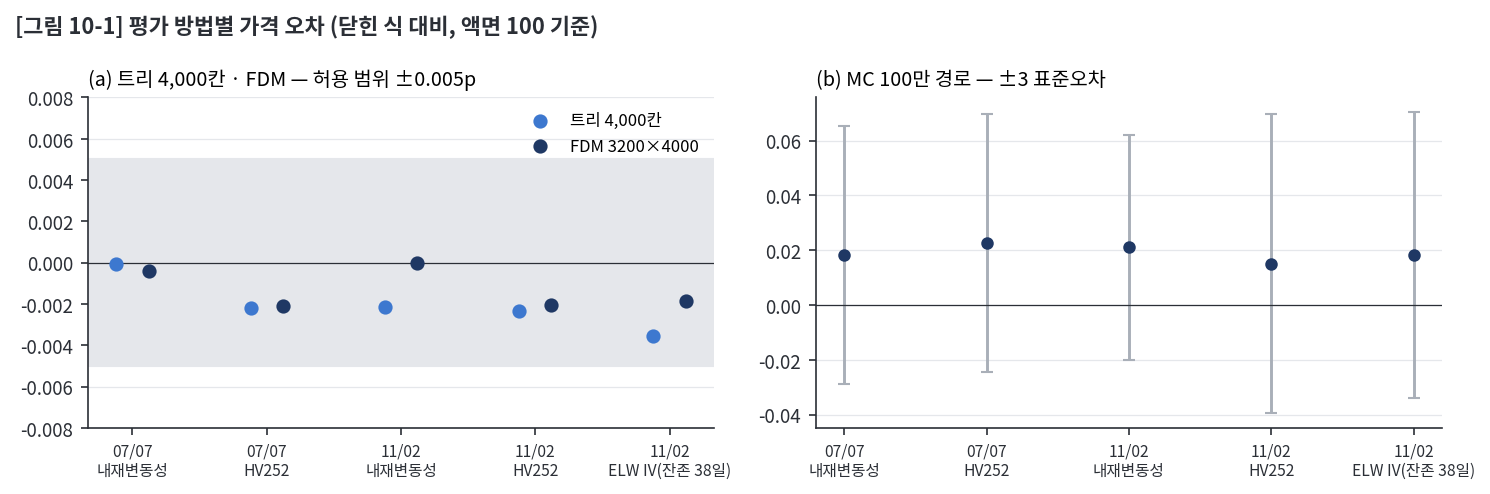

In [3]:
# 2-1 닫힌 식 점검
S, r, s = mkt(d7, '20260707'); T7 = cb.yf(d7, cb.TERMS.maturity); te7 = cb.yf(d7, cb.TERMS.conv_end); c = 100 / cb.TERMS.conv_price
B0 = 100 * math.exp(-r * (T7 - te7))
chk.check('닫힌 식: λ = 0이면 채권 + 블랙-숄즈 콜', sl.cb_exact(S, SIG, r, 0.0, d7)['price'], B0 * math.exp(-r * te7) + c * cb.bsm_call(S, B0 / c, te7, r, 0.0, SIG), 1e-10)
chk.check('닫힌 식: 전환권 제외 = 부도 회수 포함 채권가치', sl.cb_exact(S, SIG, r, s, d7, convertible=False)['price'], cb.bf_recovery(r, s, T7), 1e-10)
tp = cb.tree_params(SIG, r, s, T7 / 400); a_ = tp['disc'] * (1 - tp['p0'])   # 트리 1칸: V ← e^(−rΔt)[(1−p0)V + p0·40]
chk.check('트리 400칸: 전환권 제외 = 트리 닫힌 식', cb.cb_price(S, SIG, r, s, d7, steps=400, convertible=False),
          100 * a_ ** 400 + 40 * tp['p0'] * tp['disc'] * (1 - a_ ** 400) / (1 - a_), 1e-9)

# 2-2 평가 조건 5개 × 평가 방법 4개
TR, FD, MCN = [f'트리 {n:,}칸' for n in CFG['tree_n']], f"FDM {CFG['fdm'][0]}×{CFG['fdm'][1]}", 'MC 100만'
TOL = {TR[1]: 0.005, FD: 0.005}                                          # 가격 허용 오차(p) · delta 허용 오차 0.005
rows, MCSE = [], []
for d, k, lab, sg in CASES:
    S, r, s = mkt(d, k); ex = sl.cb_exact(S, sg, r, s, d); cn = cond(k, lab)
    def add(m_, price, delta, note=''):
        rows.append(dict(조건=cn, 방법=m_, 가격=price, 차이=price - ex['price'], delta=delta, delta차이=delta - ex['delta'], 비고=note))
    add('닫힌 식', ex['price'], ex['delta'])
    for n, nm in zip(CFG['tree_n'], TR):
        f = cb.cb_price(S, sg, r, s, d, steps=n, full=True); add(nm, f['price'], f['delta48'])
    f = sl.cb_fdm(S, sg, r, s, d, M=CFG['fdm'][0], NT=CFG['fdm'][1]); add(FD, f['price'], f['delta'], f"조기전환 칸 {f['early']}")
    m = sl.cb_mc(S, sg, r, s, d, n=CFG['mc_n'], seed=CFG['seed']); add(MCN, m['price'], m['delta'], f"SE {m['se']:.4f}"); MCSE.append(m['se'])
    for x in rows[-4:]:
        nm_ = f"{cn} {x['방법']}"
        if x['방법'] in TOL:
            chk.check(f'{nm_} 가격', abs(x['차이']), 0.0, TOL[x['방법']]); chk.check(f'{nm_} delta', abs(x['delta차이']), 0.0, 0.005)
        elif x['방법'] == MCN:
            chk.check(f'{nm_} 가격 ≤ 3SE', abs(x['차이']) <= 3 * m['se'], True); chk.check(f'{nm_} delta ≤ 3SE', abs(x['delta차이']) <= 3 * m['delta_se'], True)
        else:
            chk.check(f'{nm_} 가격 (참고)', x['차이'], kind='info')
    fdm_row = next(x for x in rows[-4:] if x['방법'] == FD)               # 현재가 ±4σ√T 범위의 조기전환 칸 수
    chk.check(f'{cn} FDM 조기전환 칸 = 0', fdm_row['비고'], '조기전환 칸 0')
METH = pd.DataFrame(rows); CN = [cond(k, lab) for _, k, lab, _ in CASES]; MN = ['닫힌 식', *TR, FD, MCN]
g = METH.set_index(['방법', '조건'])
def cell(m_, c_):
    x = g.loc[(m_, c_)]
    return f"{x['가격']:.4f}" if m_ == '닫힌 식' else f"{x['차이']:+.4f}"
display(pd.DataFrame([[cell(m_, c_) for c_ in CN] for m_ in MN], index=['가격 (닫힌 식)'] + [f'오차: {m_}' for m_ in MN[1:]], columns=CN))
dmax = lambda m_: METH[METH['방법'] == m_]['delta차이'].abs().max()
print('delta 최대 오차: ' + ' · '.join(f'{m_} {dmax(m_):.4f}' for m_ in MN[1:]))
chk.check('기존 평가 일치: 7/7 HV252 가격 (트리 400칸)', g.loc[(TR[0], cond('20260707', 'HV252')), '가격'], R3['price_hv252_A'], 1e-9)
chk.check('기존 평가 일치: 11/2 내재변동성 가격 (트리 400칸)', g.loc[(TR[0], cond('20261102', '내재변동성')), '가격'], P04.loc['발행일 CB 내재변동성 유지', '가격'], 1e-9)

# [그림 10-1] 평가 방법별 가격 오차
xs = np.arange(len(CN)); xl = [c_.replace(' ', '\n', 1) for c_ in CN]
fig, (b1, b2) = plt.subplots(1, 2, figsize=(10, 3.3))
b1.axhspan(-0.005, 0.005, color='#E5E7EB', zorder=0); b1.set_ylim(-0.008, 0.008)
for m_, col, dx in [(TR[1], C2, -0.12), (FD, C3, 0.12)]:
    b1.scatter(xs + dx, METH[METH['방법'] == m_]['차이'], s=34, color=col, label=m_, zorder=3)
b1.legend(frameon=False, fontsize=8, loc='upper right'); b1.set_title('(a) 트리 4,000칸 · FDM — 허용 범위 ±0.005p')
b2.errorbar(xs, METH[METH['방법'] == MCN]['차이'], yerr=3 * np.array(MCSE), fmt='o', ms=5, color=C3, ecolor=C1, elinewidth=1.4, capsize=3)
b2.set_title('(b) MC 100만 경로 — ±3 표준오차')
for b in (b1, b2): b.axhline(0, color=rs.INK, lw=0.6); b.set_xticks(xs, xl, fontsize=7.5)
rs.finish(fig, '[그림 10-1] 평가 방법별 가격 오차 (닫힌 식 대비, 액면 100 기준)')
plt.show()

In [4]:
# 2-3 발행가 100에 해당하는 내재변동성 (이분법)
S, r, s = mkt(d7, '20260707'); FI = f"FDM {CFG['fdm_iv'][0]}×{CFG['fdm_iv'][1]}"
fns = {'닫힌 식': lambda v: sl.cb_exact(S, v, r, s, d7)['price'],
       TR[0]: lambda v: cb.cb_price(S, v, r, s, d7, steps=CFG['tree_n'][0]),
       FI: lambda v: sl.cb_fdm(S, v, r, s, d7, M=CFG['fdm_iv'][0], NT=CFG['fdm_iv'][1])['price'],
       MCN: lambda v: sl.cb_mc(S, v, r, s, d7, n=CFG['mc_n'], seed=CFG['seed'])['price']}   # 같은 시드 → σ에 대해 매끄러움
IV = pd.DataFrame([dict(방법=k, 내재변동성=cb.implied_vol(f, 100.0, lo=0.2, hi=0.6)[0]) for k, f in fns.items()])
IV['닫힌 식 대비 (%p)'] = (IV['내재변동성'] - IV['내재변동성'].iloc[0]) * 100
show(IV, {'내재변동성': '{:.4%}', '닫힌 식 대비 (%p)': '{:+.4f}'})
vega = (fns['닫힌 식'](SIG + 1e-4) - fns['닫힌 식'](SIG - 1e-4)) / 2       # σ 0.01%p당 가격 변화
se_iv = 3 * sl.cb_mc(S, SIG, r, s, d7, n=CFG['mc_n'], seed=CFG['seed'])['se'] / vega * 0.01   # MC 3SE를 %p로 환산
chk.check('내재변동성: 트리 400칸 − 닫힌 식 (%p, 참고)', IV.loc[1, '닫힌 식 대비 (%p)'], kind='info')
chk.check('내재변동성: FDM − 닫힌 식 (%p)', abs(IV.loc[2, '닫힌 식 대비 (%p)']), 0.0, 0.02)
chk.check('내재변동성: MC − 닫힌 식 (%p, 3SE)', abs(IV.loc[3, '닫힌 식 대비 (%p)']), 0.0, round(se_iv, 4))
chk.check('내재변동성: 트리 400칸 = 기존 평가', IV.loc[1, '내재변동성'], SIG, 1e-6)

,방법,내재변동성,닫힌 식 대비 (%p)
0,닫힌 식,35.2466%,+0.0000
1,트리 400칸,35.2515%,+0.0049
2,FDM 1600×2000,35.2479%,+0.0013
3,MC 100만,35.2171%,-0.0295


ℹ 내재변동성: 트리 400칸 − 닫힌 식 (%p, 참고): 0.004928521811969899
✓ 내재변동성: FDM − 닫힌 식 (%p): 0.0012687966227609149 | 기대 0.0 ±0.02
✓ 내재변동성: MC − 닫힌 식 (%p, 3SE): 0.02946674823759432 | 기대 0.0 ±0.0766
✓ 내재변동성: 트리 400칸 = 기존 평가: 0.35251519978046414 | 기대 0.3525151997106149 ±1e-06


## 3. 기존 시뮬레이션 재현
- 전략: CB 매수 + 주식 공매도(수량 = delta × 전환주식수), 매 영업일 종가에 수량 재조정
- 일별 손익 = CB 평가손익 − 공매도 평가손익 + 공매도 대금 이자 − 대차료 − 배당 − 거래비용(반 틱 + 시장충격, 논문 eq.53 · eq.54)
- 신규 헤지 함수(`sl.hedge_run`)가 기존 결과와 일치해야 4절의 손익 변화를 추가 비용의 효과로 해석할 수 있음

In [5]:
P, DL = [], []
for _, x in D.iterrows():                                             # 일별 CB 평가 (기존 시뮬레이션과 같은 입력 · 엔진)
    f = cb.cb_price(x['S'], SIG, x['r_A'], x['s_A'], x['val'], steps=CFG['tree_n'][0], full=True)
    P.append(f['price']); DL.append(f['delta48'])
M05 = pd.read_csv(INP / '05_cb_mark_daily.csv', dtype={'일자': str}, encoding='utf-8-sig')       # 기존 일별 평가가격
chk.check('일별 CB 평가가격 = 기존 시뮬레이션 (최대 차이)', float(np.max(np.abs(np.array(P) - M05['P_mark']))), 0.0, 1e-12)

def run(**kw):                                                        # 기존 시뮬레이션 설정에서 kw 항목만 변경
    return sl.hedge_run(D, P, DL, NOT, NSH, DPS, **{**dict(borrow=CFG['borrow'], tick=CFG['tick'], Y=CFG['Y']), **kw})
base = run()
B05 = pd.read_csv(INP / '05_hedge_daily_base.csv', dtype={'일자': str}, encoding='utf-8-sig')    # 기존 일별 헤지 손익
for col in ['delta', 'CB손익', '주식손익', '이자', '대차', '배당', '거래주식수', '보유공매도', '거래비용', '합계']:
    chk.check(f'재현: {col} = 기존 시뮬레이션 (최대 차이)', float((base[col] - B05[col]).abs().max()), 0.0, 1e-6)
LBL = {'CB손익': 'CB 평가손익', '주식손익': '공매도 평가손익', '이자': '공매도 대금 이자', '대차': '대차료', '배당': '배당', '거래비용': '거래비용', '합계': '일별 손익'}
v = base[['일자', 'S', 'delta', '보유공매도', *LBL]].rename(columns={'S': '주가', '보유공매도': '공매도 주식수', **LBL})
for k in LBL.values(): v[k] = v[k] / 1e8
v['주가'] = v['주가'].map('{:,.0f}'.format); v['공매도 주식수'] = v['공매도 주식수'].map('{:,.0f}'.format)
print(f"누적 손익 {base['합계'].sum() / 1e8:+.3f}억 (손익 단위: 억원, 처음 3일 · 마지막 2일)")
display(pd.concat([v.head(3), v.tail(2)]).round(4))

✓ 일별 CB 평가가격 = 기존 시뮬레이션 (최대 차이): 1.4210854715202004e-14 | 기대 0.0 ±1e-12
✓ 재현: delta = 기존 시뮬레이션 (최대 차이): 5.551115123125783e-17 | 기대 0.0 ±1e-06
✓ 재현: CB손익 = 기존 시뮬레이션 (최대 차이): 5.960464477539063e-08 | 기대 0.0 ±1e-06
✓ 재현: 주식손익 = 기존 시뮬레이션 (최대 차이): 5.960464477539063e-08 | 기대 0.0 ±1e-06
✓ 재현: 이자 = 기존 시뮬레이션 (최대 차이): 1.1641532182693481e-10 | 기대 0.0 ±1e-06
✓ 재현: 대차 = 기존 시뮬레이션 (최대 차이): 1.4551915228366852e-11 | 기대 0.0 ±1e-06
✓ 재현: 배당 = 기존 시뮬레이션 (최대 차이): 7.275957614183426e-12 | 기대 0.0 ±1e-06
✓ 재현: 거래주식수 = 기존 시뮬레이션 (최대 차이): 2.2737367544323206e-13 | 기대 0.0 ±1e-06
✓ 재현: 보유공매도 = 기존 시뮬레이션 (최대 차이): 3.637978807091713e-12 | 기대 0.0 ±1e-06
✓ 재현: 거래비용 = 기존 시뮬레이션 (최대 차이): 2.9103830456733704e-11 | 기대 0.0 ±1e-06
✓ 재현: 합계 = 기존 시뮬레이션 (최대 차이): 3.725290298461914e-09 | 기대 0.0 ±1e-06
누적 손익 +1.713억 (손익 단위: 억원, 처음 3일 · 마지막 2일)


,일자,주가,delta,공매도 주식수,CB 평가손익,공매도 평가손익,공매도 대금 이자,대차료,배당,거래비용,일별 손익
0,20260707,"109,500",0.6196,"20,570",0.0000,0.0000,0.0000,0.0000,0.0000,-0.2524,-0.2524
1,20260708,"100,700",0.5786,"19,209",-1.7638,1.8102,0.0021,-0.0003,-0.0007,-0.0038,0.0437
2,20260709,"98,900",0.5701,"18,926",-0.3779,0.3458,0.0018,-0.0003,-0.0006,-0.0004,-0.0316
77,20261030,"83,600",0.4611,"15,308",-1.1805,1.3195,0.0015,-0.0002,-0.0005,-0.0036,0.1361
78,20261102,"89,700",0.4990,"16,566",0.9206,-0.9338,0.0038,-0.0005,-0.0005,-0.0030,-0.0134


## 4. 거래비용 반영
기존 시뮬레이션에 비용을 한 항목씩 추가하여 항목별 영향을 분리

| 비용 항목 | 기준안 | 보수안 | 근거 |
|---|---|---|---|
| 조달비용 (액면 × 금리) | 국고 1년 | 국고 1년 + 200bp | 보유 약 4개월 → 1년 금리 적용 |
| 매도세 (공매도를 늘리는 매도) | 0.20% | 0.20% | 거래세 0.05% + 농특세 0.15% (2026, 코스피) |
| 슬리피지 | 반 틱 | 2틱 | 반 틱 = 호가 차이의 절반 |
| 대차료 | 연 0.5% | 연 5% | 연 0.5% = 논문 p.35 |
| 공매도 대금 이자 | 국고 1년 | 0 | 현금담보 이자 수취 |

- 보수안 수치는 비용을 크게 가정한 스트레스 값이며 근거 수치가 아님. 실제 대차료 · 이자 · 조달금리 확정 시 `CFG`만 변경
- 청산 반영 시: 11/2에 CB 매도(호가 차이 0.37%의 절반, 논문 p.34)와 공매도 상환 비용을 차감한 값

,단계,누적 손익,단계별 변화,청산 반영 시,액면 대비
0,기존 시뮬레이션,+1.713,—,+1.507,3.43%
1,+ 조달비용 (국고 1년),+1.144,-0.569,+0.938,2.29%
2,+ 매도세 0.20% = 기준안,+1.048,-0.096,+0.842,2.10%
3,+ 조달 가산금리 200bp,+0.725,-0.323,+0.519,1.45%
4,+ 슬리피지 2틱,+0.619,-0.106,+0.388,1.24%
5,+ 대차료 연 5%,+0.293,-0.326,+0.062,0.59%
6,+ 공매도 대금 이자 0 = 보수안,+0.038,-0.255,-0.193,0.08%


✓ 조달비용 = 액면 × 국고 1년(7/7 3.338%) × 118/365: 53956712.32876711 | 기대 53956712.32876712 ±0.001
✓ 매도세 = 0.20% × 매도 금액: 9585705.679564452 | 기대 9585705.679564456 ±0.001
✓ 기존 시뮬레이션의 조달비용 · 매도세 = 0: 0.0 | 기대 0.0
손익분기 조달 가산금리(국고 1년 대비, 청산 비용 제외 기준) 6.48% · 가산금리 1bp당 손익 16.2만원 감소


,기준안에서 변경한 항목,누적 손익,기준안 대비
0,조달 가산금리 50bp,+0.967,-0.081
1,조달 가산금리 100bp,+0.886,-0.162
2,슬리피지 1틱,+1.013,-0.035
3,슬리피지 2틱,+0.942,-0.106
4,대차료 연 2%,+0.939,-0.109
5,대차료 연 5%,+0.722,-0.326
6,공매도 대금 이자 0,+0.793,-0.255
7,시장충격 제외,+1.407,+0.359


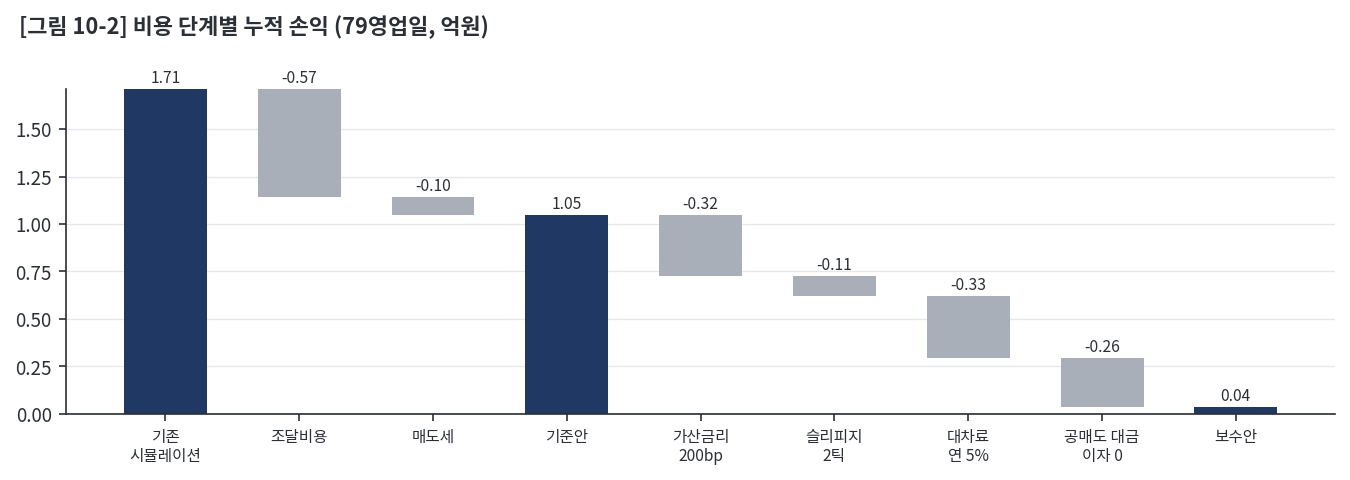

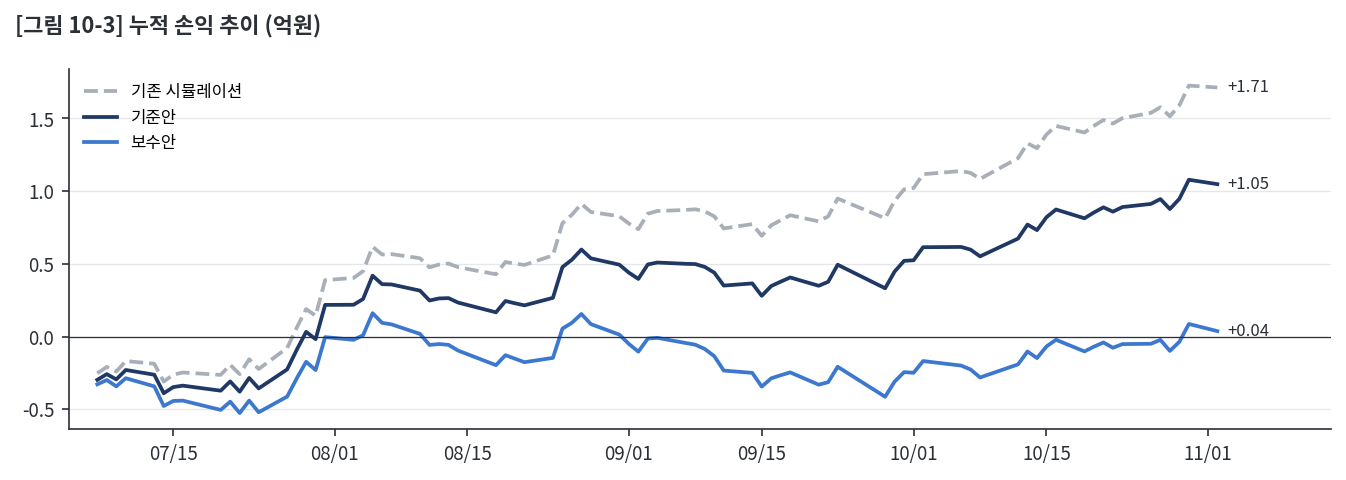

In [6]:
tot = lambda df: df['합계'].sum()
ext = lambda df, kw: tot(df) - sl.exit_cost(df, D, P[-1], NOT, CFG['cb_bidask'], CFG['tick'], kw.get('k_tick', 0.5), CFG['Y'])   # 11/2 청산 비용 차감
cons, tax = CFG['conservative'], CFG['sell_tax']
STEPS = [('기존 시뮬레이션', {}),
         ('+ 조달비용 (국고 1년)', dict(funding=0.0)),
         ('+ 매도세 0.20% = 기준안', dict(funding=0.0, sell_tax=tax)),
         ('+ 조달 가산금리 200bp', dict(funding=cons['funding'], sell_tax=tax)),
         ('+ 슬리피지 2틱', dict(funding=cons['funding'], sell_tax=tax, k_tick=cons['k_tick'])),
         ('+ 대차료 연 5%', dict(funding=cons['funding'], sell_tax=tax, k_tick=cons['k_tick'], borrow=cons['borrow'])),
         ('+ 공매도 대금 이자 0 = 보수안', dict(funding=cons['funding'], sell_tax=tax, k_tick=cons['k_tick'], borrow=cons['borrow'], rebate=0.0))]
W, runs = [], {}
for lab, kw in STEPS:
    df = run(**kw); runs[lab] = df
    W.append({'단계': lab, '누적 손익': tot(df) / 1e8, '청산 반영 시': ext(df, kw) / 1e8, '액면 대비': tot(df) / NOT})
W = pd.DataFrame(W); W.insert(2, '단계별 변화', W['누적 손익'].diff())
show(W, {'누적 손익': '{:+.3f}', '단계별 변화': '{:+.3f}', '청산 반영 시': '{:+.3f}', '액면 대비': '{:.2%}'})
STD, CON = STEPS[2][0], STEPS[-1][0]; std_run = runs[STD]

# [그림 10-2] 비용 단계별 누적 손익
lv = W['누적 손익'].to_numpy()
short = ['기존\n시뮬레이션', '조달비용', '매도세', '가산금리\n200bp', '슬리피지\n2틱', '대차료\n연 5%', '공매도 대금\n이자 0']
items = [(short[0], lv[0], 0.0, True)]
for i in range(1, len(lv)):
    items.append((short[i], lv[i] - lv[i - 1], lv[i - 1], False))
    if i == 2: items.append(('기준안', lv[2], 0.0, True))
items.append(('보수안', lv[-1], 0.0, True))
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (nm, h, b0, total) in enumerate(items):
    ax.bar(i, h, bottom=b0, width=0.62, color=C3 if total else C1)
    ax.annotate(f'{h:.2f}' if total else f'{h:+.2f}', (i, max(b0, b0 + h)), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7.5, color=rs.INK)
ax.axhline(0, color=rs.INK, lw=0.6); ax.set_xticks(range(len(items)), [x[0] for x in items], fontsize=7.5)
rs.finish(fig, '[그림 10-2] 비용 단계별 누적 손익 (79영업일, 억원)')
plt.show()

# [그림 10-3] 누적 손익 추이
fig, ax = plt.subplots(figsize=(9, 3.2))
for lab, nm, col, ls in [(STEPS[0][0], '기존 시뮬레이션', C1, '--'), (STD, '기준안', C3, '-'), (CON, '보수안', C2, '-')]:
    y = runs[lab]['합계'].cumsum() / 1e8
    ax.plot(D['val'], y, color=col, ls=ls, lw=1.8, label=nm)
    ax.annotate(f'{y.iloc[-1]:+.2f}', (D['val'].iloc[-1], y.iloc[-1]), xytext=(5, 0), textcoords='offset points', va='center', fontsize=8, color=rs.INK)
ax.axhline(0, color=rs.INK, lw=0.6); ax.set_xlim(D['val'].iloc[0] - timedelta(days=3), D['val'].iloc[-1] + timedelta(days=12))
ax.set_xticks([x for x in ax.get_xticks() if x <= mdates.date2num(D['val'].iloc[-1])])
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d')); ax.legend(frameon=False, fontsize=8, loc='upper left')
rs.finish(fig, '[그림 10-3] 누적 손익 추이 (억원)')
plt.show()

days = sum((D['val'].iloc[t] - D['val'].iloc[t - 1]).days for t in range(1, len(D)))     # 118일
Dfix = D.copy(); Dfix['ktb1'] = D['ktb1'].iloc[0]                    # 국고 1년을 7/7 값으로 고정해 손계산과 대조
fix = sl.hedge_run(Dfix, P, DL, NOT, NSH, DPS, borrow=CFG['borrow'], tick=CFG['tick'], Y=CFG['Y'], funding=0.0)
chk.check(f"조달비용 = 액면 × 국고 1년(7/7 {D['ktb1'].iloc[0]:.3f}%) × {days}/365", -fix['조달'].sum(), NOT * D['ktb1'].iloc[0] / 100 * days / 365, 1e-3)
chk.check('매도세 = 0.20% × 매도 금액', -std_run['매도세'].sum(), tax * (std_run['거래주식수'].clip(lower=0) * std_run['S']).sum(), 1e-3)
chk.check('기존 시뮬레이션의 조달비용 · 매도세 = 0', float(runs[STEPS[0][0]][['조달', '매도세']].abs().sum().sum()), 0.0)

be = tot(std_run) / (NOT * days / 365)                                    # 손익은 가산금리에 대해 선형 → 손익분기 가산금리
print(f"손익분기 조달 가산금리(국고 1년 대비, 청산 비용 제외 기준) {be:.2%} · 가산금리 1bp당 손익 {NOT * 1e-4 * days / 365 / 1e4:,.1f}만원 감소")

ONE = [('조달 가산금리 50bp', dict(funding=0.005)), ('조달 가산금리 100bp', dict(funding=0.01)), ('슬리피지 1틱', dict(k_tick=1.0)),
       ('슬리피지 2틱', dict(k_tick=2.0)), ('대차료 연 2%', dict(borrow=0.02)), ('대차료 연 5%', dict(borrow=0.05)),
       ('공매도 대금 이자 0', dict(rebate=0.0)), ('시장충격 제외', dict(Y=0.0))]
SEN = pd.DataFrame([{'기준안에서 변경한 항목': lab, '누적 손익': tot(df) / 1e8, '기준안 대비': (tot(df) - tot(std_run)) / 1e8}
                    for lab, kw in ONE for df in [run(**{**dict(funding=0.0, sell_tax=tax), **kw})]])
show(SEN, {'누적 손익': '{:+.3f}', '기준안 대비': '{:+.3f}'})

## 5. 주가 경로를 모른다고 가정한 시뮬레이션 (7/7 시점, 11번 EB와 같은 틀)
- 3 · 4절은 실제로 지나간 주가 경로 1개의 결과 → 7/7 시점에는 알 수 없었던 값
- 7/7에 알 수 있던 정보(주가 · 금리 · 스프레드 · 과거 변동성 · 과거 수익률)만으로 이후 78영업일 주가 경로 1만 개를 생성하여 손익 분포를 산출하고, 실제 결과가 분포의 어디에 위치하는지 비교
- 평가: 발행일 내재변동성으로 만든 CB 가격표(FDM, 부도 시 주가 0)에서 매일 가치 · delta를 읽음 · 금리 · 스프레드는 7/7 값으로 고정
- 시간: 1영업일 = 1/252년 (11번 EB와 같은 기준) — 78영업일 = 0.310년으로, 실제 달력 118일(0.323년)보다 시간가치 · 이자가 약 4% 적게 잡힘
- 비용: 11번 EB와 같은 항목 — 반 틱 · 시장충격(60일 평균 거래량 기준) · 매도세 0.20% · 대차료 연 0.5%, 공매도 대금 이자와 CB 매입대금 조달은 모형 금리 r, 배당은 논문 eq.53으로 따로 표시
- 청산 반영 시: 78영업일째 CB 매도(호가 차이 0.37%의 절반) + 남은 공매도 상환(반 틱 + 시장충격)을 뺀 값 — 4절 '청산 반영 시'와 같은 항목
- 부도: 하루 확률 1 − e^(−λ/252), 부도 시 CB = 40 · 주가 = 0 (공매도 이익으로 손실 일부 상쇄)

| 구분 | 주가 경로 | 목적 |
|---|---|---|
| S1 내재변동성 | GBM, σ = 발행일 내재변동성 | 엔진 점검: 모형 손익 기대값 = 0, 헤지 후 손익의 흩어짐이 충분히 작은지 |
| S2 과거 1년 변동성 | GBM, σ = HV252(7/7) | 7/7 시점 예상 |
| S3 과거 수익률 재표집 | 7/7까지 252일 일별 수익률 복원추출 (평균만 r + λ로 조정) | 7/7 시점 예상 (실제 수익률 분포) |
| 사후: 실현 변동성 | GBM, σ = 실제 79영업일(수익률 78개) 실현 변동성 | 사후 비교 — 변동성 크기의 효과와 경로의 우연을 분리 |
| 실제 경로 | 실제 종가 79영업일 | 같은 계산기로 계산한 실제 결과 |

✓ CB 가격표 7/7 가격 = 닫힌 식: 100.0022563262016 | 기대 100.0030268770217 ±0.005
✓ CB 가격표 7/7 delta = 닫힌 식: 0.6197997834091478 | 기대 0.6198507236175332 ±0.005
✓ S3 표본 252개 = HV252(7/7): True | 기대 True
7/7 입력: 주가 109,500 · r 3.9991% · s 0.6220% · 평가 σ 35.25% · HV252 75.87% · σ_D 5.58% · 60일 평균 거래량 1,073,371주 · 실제 실현 변동성(사후) 80.97%


,구분,실현 변동성,모형 손익,배당 지급,거래비용,그중 첫날,비용 후 평균,비용 후 5%,비용 후 95%,비용 후 손실 확률,청산 비용,청산 반영 시 평균,청산 반영 시 손실 확률,부도 경로,실제 결과의 분포 내 위치
0,S1 내재변동성,35.28%,-0.003,0.050,0.327,0.229,-0.381,-0.440,-0.260,100.0%,0.281,-0.663,100.0%,36,100%
1,S2 과거 1년 변동성,75.93%,+1.171,0.048,0.419,0.229,+0.704,+0.347,+1.189,0.3%,0.299,+0.405,5.5%,36,79%
2,S3 과거 수익률 재표집,75.60%,+1.194,0.048,0.403,0.229,+0.743,+0.137,+1.698,1.1%,0.297,+0.446,9.4%,36,68%
3,사후: 실현 변동성,81.03%,+1.366,0.048,0.430,0.229,+0.887,+0.459,+1.450,0.3%,0.302,+0.585,2.6%,36,54%
4,실제 경로,80.97%,+1.412,0.050,0.429,0.229,+0.933,—,—,—,0.198,+0.735,—,0,—


손익 단위: 억원 · 78영업일 · 비용 후 = 모형 손익 − 배당 지급 − 거래비용 · 청산 반영 시 = 비용 후 − 청산 비용(78영업일째 CB 매도 호가 차이 절반 + 공매도 상환)
실현 변동성 = 경로별 분산 평균의 제곱근 (아래 점검과 같은 기준) · 실제 결과의 분포 내 위치 = 비용 후 기준
모형 손익 = CB 평가손익 − 공매도 평가손익 + 공매도 대금 이자 − CB 매입대금 조달(모두 모형 금리 r) · 거래비용 = 반 틱 + 시장충격 + 매도세 + 대차료 · 배당 지급 = 논문 eq.53
✓ S1: |모형 손익 평균| ≤ 3SE: True | 기대 True
✓ S2 실현 변동성(분산 평균) ≈ HV252(7/7): 0.7593092256788369 | 기대 0.7587479916368878 ±0.005
✓ S3 실현 변동성(분산 평균) ≈ 표본 변동성: 0.7559507503081151 | 기대 0.7572410427975269 ±0.005
✓ 실제 경로 실현 변동성 = 사후 입력값: 0.8096871445399585 | 기대 0.8096871445399585 ±1e-09
✓ 헤지 효과: S1 손익 표준편차(부도 제외) ≤ 미헤지 근사의 10%: True | 기대 True
헤지 효과: S1 손익 표준편차(부도 제외) 0.055억 vs 헤지하지 않았을 때 근사 4.42억 (1.3%)
✓ 부도 경로 비율 ≈ 1 − e^(−λ·78/252) (3SE): True | 기대 True
실제 결과 +0.933억 = 7/7 예상 분포에서 S2 79% · S3 68% 위치, 사후(σ = 실현 81.0%) 분포에서 54% 위치
참고: 4절 기준안 +1.048억과의 차이는 계산 기준 차이 — 4절은 금리 · 스프레드 일별 변화, 조달 · 공매도 대금 이자 국고 1년(조달은 액면 기준), 그날 거래량 · 그날 σ_D 기준 시장충격, 트리 400칸 평가, 달력일 기준 시간을 반영


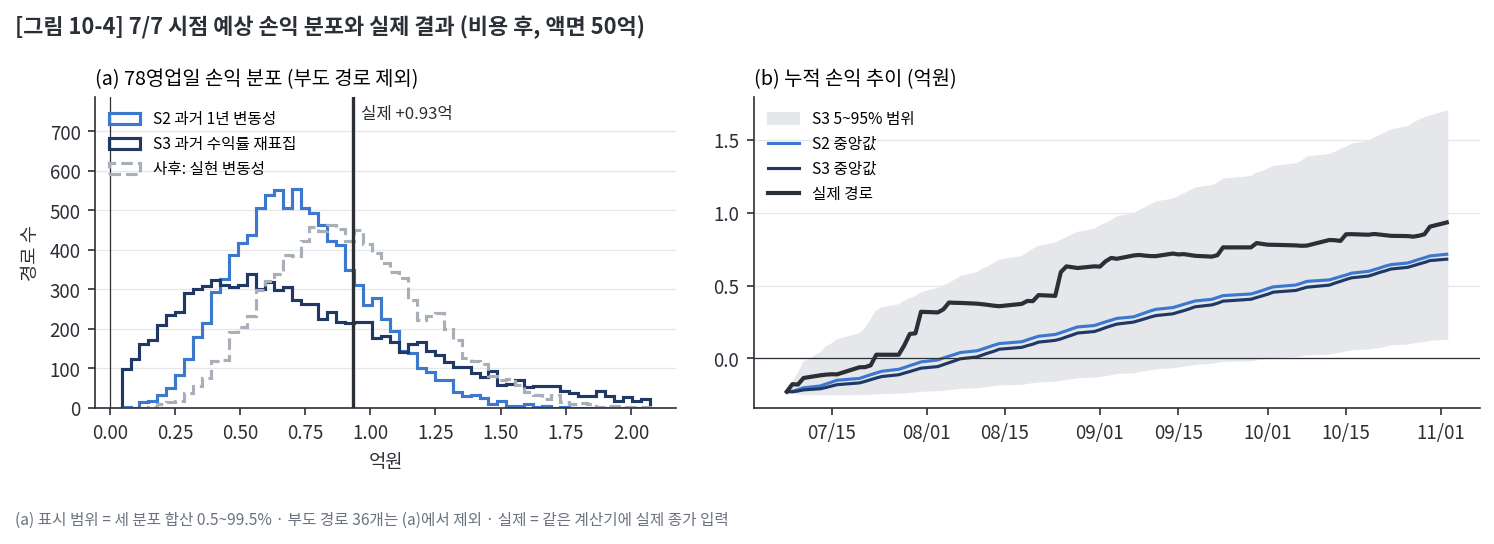

In [7]:
# 5-1 7/7 시점 입력과 CB 가격표
i0 = close.index.get_loc('20260707'); steps = len(D) - 1                 # 78영업일
RET7 = lr.iloc[i0 - 251: i0 + 1].to_numpy()                             # 7/7까지 252일 로그수익률 (S3 표본)
ADV7 = px.set_index('stck_bsop_date')['acml_vol'].astype(float).iloc[i0 - 59: i0 + 1].mean()   # 60일 평균 거래량 (7/7)
SD7, HV7 = D['sd60_daily'].iloc[0], I[('hv252', '20260707')]
REAL = float(lr.loc[D['일자']].iloc[1:].std(ddof=1) * math.sqrt(252))   # 실제 79영업일(수익률 78개) 실현 변동성 (사후 정보)
S7, r7, s7 = mkt(d7, '20260707')
G7 = sl.cb_grid(S7, SIG, r7, s7, d7, M=CFG['hedge_grid'][0], NT=CFG['hedge_grid'][1], knots=[k / 252 for k in range(1, steps + 1)])
ex7 = sl.cb_exact(S7, SIG, r7, s7, d7)
chk.check('CB 가격표 7/7 가격 = 닫힌 식', G7['price'], ex7['price'], 0.005)
chk.check('CB 가격표 7/7 delta = 닫힌 식', G7['delta'], ex7['delta'], 0.005)
chk.check('S3 표본 252개 = HV252(7/7)', abs(RET7.std(ddof=1) * math.sqrt(252) - HV7) < 1e-12, True)
print(f"7/7 입력: 주가 {S7:,.0f} · r {r7:.4%} · s {s7:.4%} · 평가 σ {SIG:.2%} · HV252 {HV7:.2%} · σ_D {SD7:.2%} · 60일 평균 거래량 {ADV7:,.0f}주 · 실제 실현 변동성(사후) {REAL:.2%}")

# 5-2 시나리오별 1만 경로 + 실제 경로 (같은 계산기)
COSTF = dict(dps=DPS, sell_tax=tax, k_tick=0.5, borrow=CFG['borrow'], Y=CFG['Y'], sd_d=SD7, adv=ADV7)
SCF = {'S1 내재변동성': dict(sigma_real=SIG), 'S2 과거 1년 변동성': dict(sigma_real=HV7),
       'S3 과거 수익률 재표집': dict(boot=RET7), '사후: 실현 변동성': dict(sigma_real=REAL)}
MCF = {k: sl.cb_hedge_mc(G7, NOT, steps, n=CFG['hedge_n'], seed=CFG['seed'], **COSTF, **v) for k, v in SCF.items()}   # 부도 난수 공통
ACT = sl.cb_hedge_mc(G7, NOT, steps, path=D['S'].values, **COSTF)
act = ACT['pnl_cost'][0] / 1e8
def rowf(k, m):
    x0, x = m['pnl'] / 1e8, m['pnl_cost'] / 1e8
    xe = sl.mc_exit_cost(m, NOT, SD7, ADV7, CFG['cb_bidask'], 0.5, CFG['Y']) / 1e8; xx = x - xe   # 청산 반영 시
    return {'구분': k, '실현 변동성': float(np.sqrt(np.nanmean(m['vol'] ** 2))), '모형 손익': x0.mean(), '표준오차': x0.std(ddof=1) / math.sqrt(len(x0)) if len(x0) > 1 else np.nan,
            '배당 지급': m['div'].mean() / 1e8, '거래비용': m['cost'].mean() / 1e8, '그중 첫날': m['cost0'].mean() / 1e8, '비용 후 평균': x.mean(),
            '비용 후 5%': np.percentile(x, 5), '비용 후 95%': np.percentile(x, 95), '비용 후 손실 확률': (x < 0).mean(),
            '청산 비용': xe.mean(), '청산 반영 시 평균': xx.mean(), '청산 반영 시 손실 확률': (xx < 0).mean(),
            '부도 경로': m['defaults'], '실제 결과의 분포 내 위치': (x < act).mean()}
HF = pd.DataFrame([rowf(k, m) for k, m in MCF.items()] + [rowf('실제 경로', ACT)])
HF.loc[HF['구분'] == '실제 경로', ['표준오차', '비용 후 5%', '비용 후 95%', '비용 후 손실 확률', '청산 반영 시 손실 확률', '실제 결과의 분포 내 위치']] = np.nan
show(HF.drop(columns='표준오차'), {**{k: '{:+.3f}' for k in ['모형 손익', '비용 후 평균', '비용 후 5%', '비용 후 95%', '청산 반영 시 평균']},
                                  **{k: '{:.3f}' for k in ['배당 지급', '거래비용', '그중 첫날', '청산 비용']},
                                  '실현 변동성': '{:.2%}', '비용 후 손실 확률': '{:.1%}', '청산 반영 시 손실 확률': '{:.1%}', '실제 결과의 분포 내 위치': '{:.0%}'})
print('손익 단위: 억원 · 78영업일 · 비용 후 = 모형 손익 − 배당 지급 − 거래비용 · 청산 반영 시 = 비용 후 − 청산 비용(78영업일째 CB 매도 호가 차이 절반 + 공매도 상환)')
print('실현 변동성 = 경로별 분산 평균의 제곱근 (아래 점검과 같은 기준) · 실제 결과의 분포 내 위치 = 비용 후 기준')
print('모형 손익 = CB 평가손익 − 공매도 평가손익 + 공매도 대금 이자 − CB 매입대금 조달(모두 모형 금리 r) · 거래비용 = 반 틱 + 시장충격 + 매도세 + 대차료 · 배당 지급 = 논문 eq.53')
nd = MCF['S1 내재변동성']['defaults']; pdf = 1 - math.exp(-G7['lam'] * steps / 252)
chk.check('S1: |모형 손익 평균| ≤ 3SE', bool(abs(HF.loc[0, '모형 손익']) <= 3 * HF.loc[0, '표준오차']), True)
rms = lambda k: float(np.sqrt(np.nanmean(MCF[k]['vol'] ** 2)))         # 경로별 분산 평균의 제곱근 (경로별 표준편차 평균은 하향 편향)
chk.check('S2 실현 변동성(분산 평균) ≈ HV252(7/7)', rms('S2 과거 1년 변동성'), HV7, 0.005)
chk.check('S3 실현 변동성(분산 평균) ≈ 표본 변동성', rms('S3 과거 수익률 재표집'), RET7.std(ddof=0) * math.sqrt(252), 0.005)
chk.check('실제 경로 실현 변동성 = 사후 입력값', ACT['vol'][0], REAL, 1e-9)
m1 = MCF['S1 내재변동성']; sd1 = float((m1['pnl'][~m1['dflt']] / 1e8).std(ddof=1))
sd0 = G7['delta'] * NSH * S7 * SIG * math.sqrt(steps / 252) / 1e8      # 헤지하지 않았을 때 손익 표준편차 근사 = delta × 전환주식수 × 주가 × σ√T
chk.check('헤지 효과: S1 손익 표준편차(부도 제외) ≤ 미헤지 근사의 10%', bool(sd1 <= 0.1 * sd0), True)
print(f"헤지 효과: S1 손익 표준편차(부도 제외) {sd1:.3f}억 vs 헤지하지 않았을 때 근사 {sd0:.2f}억 ({sd1 / sd0:.1%})")
chk.check('부도 경로 비율 ≈ 1 − e^(−λ·78/252) (3SE)', abs(nd / CFG['hedge_n'] - pdf) <= 3 * math.sqrt(pdf * (1 - pdf) / CFG['hedge_n']), True)
print(f"실제 결과 {act:+.3f}억 = 7/7 예상 분포에서 S2 {HF.loc[1, '실제 결과의 분포 내 위치']:.0%} · S3 {HF.loc[2, '실제 결과의 분포 내 위치']:.0%} 위치, "
      f"사후(σ = 실현 {REAL:.1%}) 분포에서 {HF.loc[3, '실제 결과의 분포 내 위치']:.0%} 위치")
print(f"참고: 4절 기준안 {lv[2]:+.3f}억과의 차이는 계산 기준 차이 — 4절은 금리 · 스프레드 일별 변화, 조달 · 공매도 대금 이자 국고 1년(조달은 액면 기준), 그날 거래량 · 그날 σ_D 기준 시장충격, 트리 400칸 평가, 달력일 기준 시간을 반영")

# [그림 10-4] 7/7 시점 예상 vs 실제
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={'width_ratios': [1, 1.25]})
ks = ['S2 과거 1년 변동성', 'S3 과거 수익률 재표집', '사후: 실현 변동성']; COLF = dict(zip(ks, (C2, C3, C1))); LSF = dict(zip(ks, ('-', '-', '--')))
okf = {k: MCF[k]['pnl_cost'][~MCF[k]['dflt']] / 1e8 for k in ks}
bins = np.linspace(*np.percentile(np.concatenate(list(okf.values())), [0.5, 99.5]), 60)
for k in ks: a1.hist(okf[k], bins=bins, histtype='step', lw=1.5, color=COLF[k], ls=LSF[k], label=k)
a1.set_ylim(0, a1.get_ylim()[1] * 1.35)                                # 범례 · 표시용 위쪽 여백
a1.axvline(act, color=rs.INK, lw=1.6); a1.annotate(f'실제 {act:+.2f}억', (act, a1.get_ylim()[1] * 0.93), xytext=(4, 0), textcoords='offset points', fontsize=8, color=rs.INK)
a1.axvline(0, color=rs.INK, lw=0.6); a1.legend(frameon=False, fontsize=7.5, loc='upper left', ncol=1); a1.set_xlabel('억원'); a1.set_ylabel('경로 수')
a1.set_title('(a) 78영업일 손익 분포 (부도 경로 제외)')
cum3 = MCF['S3 과거 수익률 재표집']['cum'] / 1e8
a2.fill_between(D['val'], np.percentile(cum3, 5, axis=1), np.percentile(cum3, 95, axis=1), color='#E5E7EB', label='S3 5~95% 범위')
a2.plot(D['val'], np.median(MCF['S2 과거 1년 변동성']['cum'] / 1e8, axis=1), color=C2, lw=1.5, label='S2 중앙값')
a2.plot(D['val'], np.median(cum3, axis=1), color=C3, lw=1.5, label='S3 중앙값')
a2.plot(D['val'], ACT['cum'][:, 0] / 1e8, color=rs.INK, lw=2.0, label='실제 경로')
a2.axhline(0, color=rs.INK, lw=0.6); a2.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d')); a2.legend(frameon=False, fontsize=7.5, loc='upper left')
a2.set_title('(b) 누적 손익 추이 (억원)')
rs.finish(fig, '[그림 10-4] 7/7 시점 예상 손익 분포와 실제 결과 (비용 후, 액면 50억)', f'(a) 표시 범위 = 세 분포 합산 0.5~99.5% · 부도 경로 {nd}개는 (a)에서 제외 · 실제 = 같은 계산기에 실제 종가 입력')
plt.show()

## 6. 국채선물 금리 헤지 (실제 79영업일)
- 목적: 3 · 4절 델타 헤지는 주가 위험만 제거 → CB 평가손익에 남은 국고 금리 변화의 영향을 국채선물 매도로 제거
- 선물: **3년 국채선물** — 5년 국채선물은 같은 기간 거래가 거의 없어(6-1 출력: 거래량 · 미결제약정) 매일 수량 조정이 불가능
- CB 금리 민감도(DV01): 3절과 같은 트리 400칸 · 내재변동성 고정에서 국고 금리 r만 ±1bp(신용스프레드 s 고정) → 금리 1bp 상승 시 CB 손실(원)
- 선물 1계약 DV01: 국채선물 가격식(표면 연 5% · 6개월 이자 · 만기 3년, 액면 1억원, 1pt = 100만원)으로 정산가 → 수익률 → ±1bp
- 계약 수 = CB DV01 ÷ 선물 1계약 DV01 (정수 반올림), 매 영업일 정산가로 조정 · 9월물은 최종거래일(9/15) 5영업일 전에 12월물로 교체
- 손익 = −전날 계약 수 × 정산가 변화 × 100만원 · 비용 = 거래 계약당 반 틱(0.005pt = 5,000원) · 증거금 조달 · 위탁수수료 · 시장충격은 미반영
- 효과: CB 손익의 금리 요인(기존 시뮬레이션 원인 분해 `dP_금리`)과 선물 손익을 날짜별로 비교 → 남는 차이 = CB 잔존 만기(약 5년) 국고 금리와 3년 선물 수익률의 움직임 차이 (현물 커브 변화 + 선물 가격이 만기로 갈수록 현물에 다가가는 수렴)
- 6-4: 그 차이를 현물 금리 변화분과 나머지(CB: 잔존 만기 감소, 선물: 현물로 수렴)로 근사 분해 (ECOS 국고 원자료)

,종류,월물,거래일,일평균_거래량,최대_미결제약정
0,10y,202609,49,"77,136","317,746"
1,10y,202612,79,"39,212","284,410"
2,10y,202703,30,0,11
3,3y,202609,49,"163,091","597,425"
4,3y,202612,79,"73,308","509,214"
5,3y,202703,30,1,12
6,5y,202609,49,3,47
7,5y,202612,79,0,0
8,5y,202703,30,0,0


7/7 ~ 11/2 주간 거래 기준 · 5년물 거래가 거의 없어 3년물로 헤지
✓ 9월물 마지막 정산가 날짜 = 최종거래일 9/15: 20260915 | 기대 20260915
✓ 보유 월물 정산가 결측 없음 (79영업일): True | 기대 True
✓ 국채선물 가격식 왕복: 가격 → 수익률 → 가격: 4.263256414560601e-14 | 기대 0.0 ±1e-09
롤오버: 20260908 종가에 202609 → 202612 (최종거래일 20260915의 5영업일 전)
ℹ DV01 × 국고 금리 변화 ≈ 원인 분해 금리 요인 (일별 상관): 0.9994414149827552  (합계 +0.224억 vs +0.229억)
✓ 선물 비용 = 거래 계약 수 × 5,000원: 1095000.0 | 기대 1095000.0 ±1e-06
ℹ 일별 금리 변화 상관: CB 국고 금리 r vs 3년 선물 수익률: 0.9581935718207515  (표준편차 r 4.45bp · 선물 4.84bp · 79영업일 누적 변화 r -13.1bp · 선물 -27.3bp)


,항목,합계 (억원),일별 표준편차 (만원)
0,CB 손익 중 금리 요인 (헤지 전),+0.2291,580.8
1,선물 손익,-0.4221,627.5
2,금리 요인 + 선물 손익 (헤지 후),-0.1930,184.2
3,선물 비용 (반 틱),-0.0109,—


계약 수 39~55계약 매도 (CB DV01 110~156만원/bp, 선물 1계약 28,197~28,725원/bp) · 거래 219계약
금리 요인 일별 표준편차 68% 감소 · 기준안 누적 +1.048억 → 금리 헤지 포함 +0.615억 (청산 반영 시 +0.842억 → +0.406억, 선물 환매 25.5만원 포함)
일별 전체 손익(기준안) 표준편차 749만원 → 금리 헤지 포함 357만원 (첫날 제외)


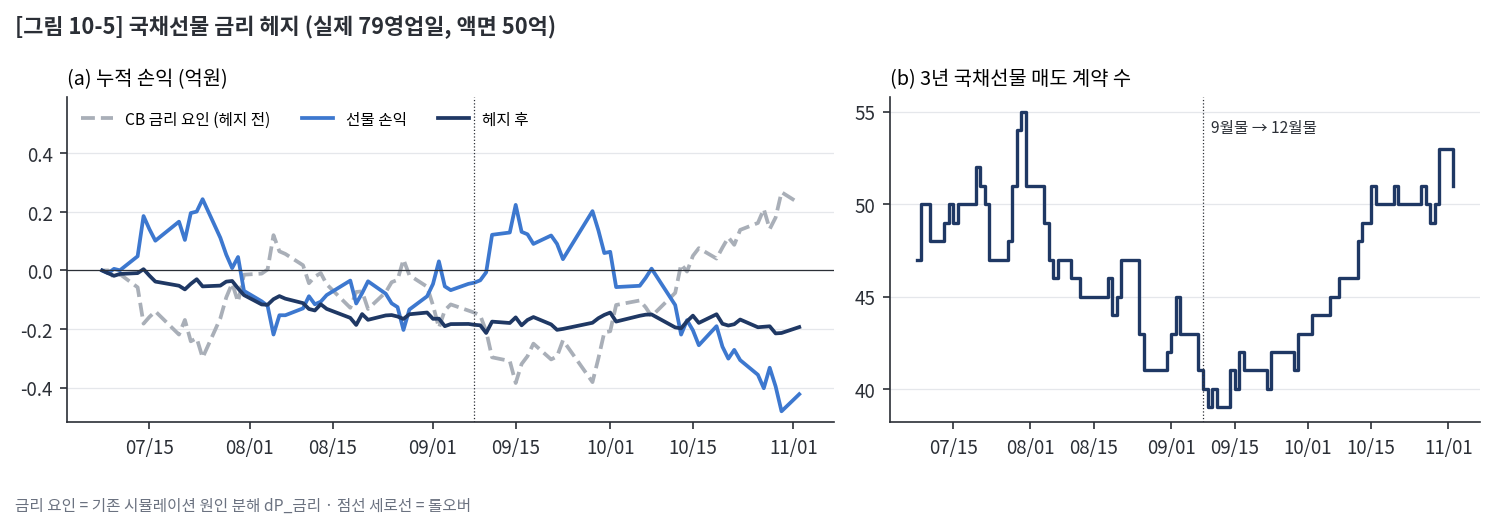

In [8]:
# 6-1 국채선물 원자료 (KRX 선물 개별종목 시세 추이, 주간 정산가)
RF = dict(file=PROJ / 'data' / '20261109' / 'krx_ktbf_daily_20260701_20261106.csv',   # KRX MDCSTAT12601 원자료 (9종목)
          kind='3y', n_years=3, near='202609', next='202612', near_last='20260915',  # 3년 국채선물 · 9월물 최종거래일
          roll_days=5, mult=1_000_000, tick=0.01, k_tick=0.5)                        # 롤오버 5영업일 전 · 1pt = 100만원 · 호가단위 0.01pt · 반 틱
KRX = pd.read_csv(RF['file'], dtype=str, encoding='utf-8-sig')
KRX['일자'] = KRX['TRD_DD'].str[:10].str.replace('/', ''); KRX = KRX[~KRX['TRD_DD'].str.contains('야간')]   # 주간 거래 (5년물은 야간 없음)
for k in ['SETL_PRC', 'ACC_TRDVOL', 'ACC_OPNINT_QTY']: KRX[k] = pd.to_numeric(KRX[k].str.replace(',', ''), errors='coerce')
win = KRX['일자'].between(D['일자'].iloc[0], D['일자'].iloc[-1])
LIQ = KRX[win].groupby(['종류', '월물']).agg(거래일=('일자', 'size'), 일평균_거래량=('ACC_TRDVOL', 'mean'), 최대_미결제약정=('ACC_OPNINT_QTY', 'max')).reset_index()
show(LIQ, {'일평균_거래량': '{:,.0f}', '최대_미결제약정': '{:,.0f}'})
print('7/7 ~ 11/2 주간 거래 기준 · 5년물 거래가 거의 없어 3년물로 헤지')
FUT = KRX[KRX['종류'] == RF['kind']].pivot(index='일자', columns='월물', values='SETL_PRC')
px_f = FUT.reindex(D['일자'])[[RF['near'], RF['next']]].reset_index(drop=True)          # CB 79영업일에 맞춘 정산가
i_last = int(D.index[D['일자'] == RF['near_last']][0]); i_roll = i_last - RF['roll_days']
held = [RF['near'] if t < i_roll else RF['next'] for t in range(len(D))]               # 그날 종가 이후 보유 월물
chk.check('9월물 마지막 정산가 날짜 = 최종거래일 9/15', FUT[RF['near']].dropna().index.max(), RF['near_last'])
chk.check('보유 월물 정산가 결측 없음 (79영업일)', bool(all(pd.notna(px_f[c].iloc[t]) for t, c in enumerate(held)) and px_f[RF['near']].iloc[:i_roll + 1].notna().all()), True)
Pt = float(px_f[RF['next']].iloc[-1])
chk.check('국채선물 가격식 왕복: 가격 → 수익률 → 가격', abs(sl.ktbf_price(sl.ktbf_yield(Pt, 3), 3) - Pt), 0.0, 1e-9)
print(f"롤오버: {D['일자'].iloc[i_roll]} 종가에 {RF['near']} → {RF['next']} (최종거래일 {RF['near_last']}의 {RF['roll_days']}영업일 전)")

# 6-2 CB 금리 민감도 (DV01) 와 선물 헤지
hb = 1e-4; DV = []
for _, x in D.iterrows():                                             # 3절과 같은 엔진 · 입력, 국고 금리 r만 ±1bp
    up = cb.cb_price(x['S'], SIG, x['r_A'] + hb, x['s_A'], x['val'], steps=CFG['tree_n'][0])
    dn = cb.cb_price(x['S'], SIG, x['r_A'] - hb, x['s_A'], x['val'], steps=CFG['tree_n'][0])
    DV.append((dn - up) / 2 * NOT / 100)                              # 금리 1bp 상승 시 CB 손실(원)
DV = np.array(DV)
RATE = (M05['dP_금리'].fillna(0.0) * NOT / 100).to_numpy()             # 기존 원인 분해: CB 손익 중 금리 요인(원)
est = np.r_[0.0, -DV[:-1] * np.diff(D['r_A'].to_numpy()) * 1e4]          # DV01 × 금리 변화(bp)로 다시 만든 금리 요인
chk.check('DV01 × 국고 금리 변화 ≈ 원인 분해 금리 요인 (일별 상관)', float(np.corrcoef(RATE[1:], est[1:])[0, 1]), basis=f"합계 {est.sum() / 1e8:+.3f}억 vs {RATE.sum() / 1e8:+.3f}억", kind='info')
H = sl.ktbf_hedge(px_f, held, DV, RF['n_years'], RF['mult'], RF['tick'], RF['k_tick'])
H.insert(0, '일자', D['일자'].values); H['CB금리요인'] = RATE
chk.check('선물 비용 = 거래 계약 수 × 5,000원', -H['선물비용'].sum(), H['거래계약'].sum() * RF['k_tick'] * RF['tick'] * RF['mult'], 1e-6)
yf_ = np.array([sl.ktbf_yield(float(px_f[c].iloc[t]), 3) for t, c in enumerate(held)])   # 보유 월물 정산가의 수익률
dy_f = np.array([(sl.ktbf_yield(float(px_f[held[t - 1]].iloc[t]), 3) - yf_[t - 1]) * 1e4 for t in range(1, len(D))])   # 전날 보유 월물 기준 (bp)
dr = np.diff(D['r_A'].to_numpy()) * 1e4
chk.check('일별 금리 변화 상관: CB 국고 금리 r vs 3년 선물 수익률', float(np.corrcoef(dr, dy_f)[0, 1]), basis=f"표준편차 r {dr.std(ddof=1):.2f}bp · 선물 {dy_f.std(ddof=1):.2f}bp · 79영업일 누적 변화 r {dr.sum():+.1f}bp · 선물 {dy_f.sum():+.1f}bp", kind='info')

# 6-3 효과
x_out = H['계약수'].iloc[-1] * RF['k_tick'] * RF['tick'] * RF['mult']    # 11/2 선물 환매 비용 (청산 반영 시)
sd = lambda a: float(np.std(np.asarray(a)[1:], ddof=1))
after = RATE + H['선물손익'].to_numpy()
RH = pd.DataFrame([
    {'항목': 'CB 손익 중 금리 요인 (헤지 전)', '합계 (억원)': RATE.sum() / 1e8, '일별 표준편차 (만원)': sd(RATE) / 1e4},
    {'항목': '선물 손익', '합계 (억원)': H['선물손익'].sum() / 1e8, '일별 표준편차 (만원)': sd(H['선물손익']) / 1e4},
    {'항목': '금리 요인 + 선물 손익 (헤지 후)', '합계 (억원)': after.sum() / 1e8, '일별 표준편차 (만원)': sd(after) / 1e4},
    {'항목': '선물 비용 (반 틱)', '합계 (억원)': H['선물비용'].sum() / 1e8, '일별 표준편차 (만원)': np.nan}])
show(RH, {'합계 (억원)': '{:+.4f}', '일별 표준편차 (만원)': '{:,.1f}'})
cut = 1 - sd(after) / sd(RATE)
tot_r = tot(std_run) + H['선물손익'].sum() + H['선물비용'].sum(); ext_r = ext(std_run, {}) + H['선물손익'].sum() + H['선물비용'].sum() - x_out
print(f"계약 수 {H['계약수'].min()}~{H['계약수'].max()}계약 매도 (CB DV01 {DV.min() / 1e4:,.0f}~{DV.max() / 1e4:,.0f}만원/bp, 선물 1계약 {H['선물DV01'].min():,.0f}~{H['선물DV01'].max():,.0f}원/bp) · 거래 {H['거래계약'].sum():,}계약")
print(f"금리 요인 일별 표준편차 {cut:.0%} 감소 · 기준안 누적 {tot(std_run) / 1e8:+.3f}억 → 금리 헤지 포함 {tot_r / 1e8:+.3f}억 (청산 반영 시 {ext(std_run, {}) / 1e8:+.3f}억 → {ext_r / 1e8:+.3f}억, 선물 환매 {x_out / 1e4:,.1f}만원 포함)")
print(f"일별 전체 손익(기준안) 표준편차 {sd(std_run['합계']) / 1e4:,.0f}만원 → 금리 헤지 포함 {sd(std_run['합계'] + H['선물손익'] + H['선물비용']) / 1e4:,.0f}만원 (첫날 제외)")

# [그림 10-5] 국채선물 금리 헤지
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={'width_ratios': [1.3, 1]})
for y_, nm, col, ls in [(RATE, 'CB 금리 요인 (헤지 전)', C1, '--'), (H['선물손익'], '선물 손익', C2, '-'), (after, '헤지 후', C3, '-')]:
    a1.plot(D['val'], np.cumsum(y_) / 1e8, color=col, ls=ls, lw=1.8, label=nm)
a1.axhline(0, color=rs.INK, lw=0.6); a1.axvline(D['val'].iloc[i_roll], color=rs.INK, lw=0.6, ls=':')
lo_, hi_ = a1.get_ylim(); a1.set_ylim(lo_, hi_ + 0.35 * (hi_ - lo_))                    # 범례용 위쪽 여백
a1.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d')); a1.legend(frameon=False, fontsize=7.5, loc='upper left', ncol=3); a1.set_title('(a) 누적 손익 (억원)')
a2.step(D['val'], H['계약수'], where='post', color=C3, lw=1.6); a2.axvline(D['val'].iloc[i_roll], color=rs.INK, lw=0.6, ls=':')
a2.annotate('9월물 → 12월물', (D['val'].iloc[i_roll], H['계약수'].max()), xytext=(4, -10), textcoords='offset points', fontsize=7.5, color=rs.INK)
a2.yaxis.get_major_locator().set_params(integer=True)                                # 계약 수 = 정수 눈금
a2.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d')); a2.set_title('(b) 3년 국채선물 매도 계약 수')
rs.finish(fig, '[그림 10-5] 국채선물 금리 헤지 (실제 79영업일, 액면 50억)', '금리 요인 = 기존 시뮬레이션 원인 분해 dP_금리 · 점선 세로선 = 롤오버')
plt.show()

In [9]:
# 6-4 선물 손익이 금리 요인보다 큰 이유 (근사 분해: 현물 국고 = ECOS 원자료, 01_daily와 같은 출처)
EC = pd.read_csv(PROJ / 'data' / '20261103' / 'ecos_817Y002_ktb_daily_20260707_20261102.csv', dtype={'조회일자': str}, encoding='utf-8-sig')
EC['만기'] = EC['항목명'].str.extract(r'\((\d+)년\)')[0].astype(int)           # '국고채(3년)' → 3
CV = EC.pivot(index='조회일자', columns='만기', values='값').reindex(D['일자'])           # 날짜 × 만기 국고 금리(%)
ri = np.array([cb.interp_ktb(CV.iloc[t].to_dict(), D['T'].iloc[t]) for t in range(len(D))])
chk.check('ECOS 국고 커브 보간 = CB 금리 r (79일 최대 차이)', float(np.abs(ri / 100 - D['r_A'].to_numpy()).max()), 0.0, 1e-12)
mid = np.array([cb.interp_ktb(CV.iloc[t].to_dict(), D['T'].iloc[t - 1]) for t in range(1, len(D))])   # 오늘 커브 · 어제 잔존 만기
dr_m, dr_t = (mid - ri[:-1]) * 100, (ri[1:] - mid) * 100                 # r 변화(bp) = 커브 이동분 + 잔존 만기 감소분
dy3 = np.diff(CV[3].to_numpy()) * 100                                    # 현물 국고 3년 변화(bp)
fdv = (H['계약수'] * H['선물DV01']).to_numpy()[:-1]                      # 전날 매도 계약 × 1계약 DV01 (원/bp)
DEC6 = pd.DataFrame([
    {'구분': 'CB 금리 요인 ≈ −DV01 × r 변화', '현물 금리 변화분': (-DV[:-1] * dr_m).sum() / 1e8, '나머지': (-DV[:-1] * dr_t).sum() / 1e8, '실제 합계': RATE.sum() / 1e8},
    {'구분': '선물 손익 ≈ 계약 × DV01 × 선물 수익률 변화', '현물 금리 변화분': (fdv * dy3).sum() / 1e8, '나머지': (fdv * (dy_f - dy3)).sum() / 1e8, '실제 합계': H['선물손익'].sum() / 1e8}])
show(DEC6, {k: '{:+.3f}' for k in DEC6.columns[1:]})
print('억원 · 일별 선형 근사(두 분해의 합과 실제 합계의 차이 = 곡률) · 현물 금리 = ECOS 국고(CB: 같은 잔존 만기로 보간, 선물: 3년) · 나머지 = CB: 잔존 만기 감소, 선물: 선물 − 현물 차이 축소(수렴)')
print(f"79일 변화: 국고 3년 {dy3.sum():+.1f}bp · 5년 {(CV[5].iloc[-1] - CV[5].iloc[0]) * 100:+.1f}bp (5년 − 3년 {(CV[5].iloc[0] - CV[3].iloc[0]) * 100:.1f} → {(CV[5].iloc[-1] - CV[3].iloc[-1]) * 100:.1f}bp) · "
      f"CB r {dr.sum():+.1f}bp (커브 {dr_m.sum():+.1f} · 잔존 만기 감소 {dr_t.sum():+.1f}) · 3년 선물 수익률 {dy_f.sum():+.1f}bp (현물 3년 {dy3.sum():+.1f} · 선물 − 현물 차이 축소 {(dy_f - dy3).sum():+.1f})")
bs = lambda t, c: (sl.ktbf_yield(float(px_f[c].iloc[t]), 3) - CV[3].iloc[t] / 100) * 1e4   # 선물 수익률 − 현물 국고 3년 (bp)
print(f"선물 − 현물 3년 차이: 9월물 {bs(0, RF['near']):+.1f}bp(7/7) → {bs(i_roll, RF['near']):+.1f}bp(롤오버일) · 12월물 {bs(i_roll, RF['next']):+.1f}bp(롤오버일) → {bs(len(D) - 1, RF['next']):+.1f}bp(11/2) — 만기로 갈수록 현물에 다가감")
chk.check('선물 손익 분해 합 ≈ 실제 (선형 근사)', float(DEC6.iloc[1, 1] + DEC6.iloc[1, 2]), basis=f"실제 {H['선물손익'].sum() / 1e8:+.4f}억", kind='info')

✓ ECOS 국고 커브 보간 = CB 금리 r (79일 최대 차이): 9.71445146547012e-17 | 기대 0.0 ±1e-12


,구분,현물 금리 변화분,나머지,실제 합계
0,CB 금리 요인 ≈ −DV01 × r 변화,+0.179,+0.045,+0.229
1,선물 손익 ≈ 계약 × DV01 × 선물 수익률 변화,-0.107,-0.311,-0.422


억원 · 일별 선형 근사(두 분해의 합과 실제 합계의 차이 = 곡률) · 현물 금리 = ECOS 국고(CB: 같은 잔존 만기로 보간, 선물: 3년) · 나머지 = CB: 잔존 만기 감소, 선물: 선물 − 현물 차이 축소(수렴)
79일 변화: 국고 3년 -4.0bp · 5년 -10.7bp (5년 − 3년 21.9 → 15.2bp) · CB r -13.1bp (커브 -9.7 · 잔존 만기 감소 -3.5) · 3년 선물 수익률 -27.3bp (현물 3년 -4.0 · 선물 − 현물 차이 축소 -23.3)
선물 − 현물 3년 차이: 9월물 +11.5bp(7/7) → -0.9bp(롤오버일) · 12월물 +16.3bp(롤오버일) → +5.4bp(11/2) — 만기로 갈수록 현물에 다가감
ℹ 선물 손익 분해 합 ≈ 실제 (선형 근사): -0.41815952937428036  (실제 -0.4221억)


## 7. 요약

In [10]:
gm = lambda m_: METH[METH['방법'] == m_]['차이'].abs().max()
SUMM = pd.DataFrame([
    dict(항목='① 평가 방법 비교', 결과=f"닫힌 식 대비 최대 오차: 트리 4,000칸 {gm(TR[1]):.4f}p · FDM {gm(FD):.4f}p · MC {gm(MCN):.4f}p(3SE 이내) · 내재변동성 FDM {IV.loc[2, '닫힌 식 대비 (%p)']:+.4f}%p", 근거='2절'),
    dict(항목='② 거래비용 반영', 결과=f"누적 손익: 기존 시뮬레이션 {lv[0]:+.2f}억 → 기준안 {lv[2]:+.2f}억 → 보수안 {lv[-1]:+.2f}억 · 손익분기 조달 가산금리 {be:.2%}(청산 비용 제외)", 근거='4절'),
    dict(항목='③ 7/7 시점 예상 vs 실제', 결과=f"예상(비용 후 평균): S2 {HF.loc[1, '비용 후 평균']:+.2f}억 · S3 {HF.loc[2, '비용 후 평균']:+.2f}억 → 실제 {act:+.2f}억 (S2 분포 {HF.loc[1, '실제 결과의 분포 내 위치']:.0%} · 사후 분포 {HF.loc[3, '실제 결과의 분포 내 위치']:.0%} 위치) · 청산 반영 시 S2 {HF.loc[1, '청산 반영 시 평균']:+.2f}억 · 실제 {HF.loc[4, '청산 반영 시 평균']:+.2f}억", 근거='5절'),
    dict(항목='④ 국채선물 금리 헤지', 결과=f"3년 국채선물 {H['계약수'].min()}~{H['계약수'].max()}계약 매도 · 금리 요인 {RATE.sum() / 1e8:+.3f}억 + 선물 {H['선물손익'].sum() / 1e8:+.3f}억 = {after.sum() / 1e8:+.3f}억 (선물 손익 중 선물 − 현물 수렴분 약 {DEC6.iloc[1, 2]:+.2f}억) · 일별 표준편차 {cut:.0%} 감소 · 기준안 {tot(std_run) / 1e8:+.3f}억 → {tot_r / 1e8:+.3f}억 (청산 반영 시 {ext_r / 1e8:+.3f}억)", 근거='6절')])
show(SUMM)
for name, df in [('methods', METH), ('iv', IV), ('cost_waterfall', W), ('cost_sensitivity', SEN), ('hedge_daily_standard', std_run), ('hedge_mc', HF), ('rate_hedge_daily', H), ('rate_hedge', RH), ('rate_decomposition', DEC6)]:
    df.to_csv(OUT / f'10_{name}.csv', index=False, encoding='utf-8-sig')
assert chk.save(OUT / '10_checks.csv') == 0, '✗ 항목 확인'

,항목,결과,근거
0,① 평가 방법 비교,"닫힌 식 대비 최대 오차: 트리 4,000칸 0.0036p · FDM 0.0021p · MC 0.0227p(3SE 이내) · 내재변동성 FDM +0.0013%p",2절
1,② 거래비용 반영,누적 손익: 기존 시뮬레이션 +1.71억 → 기준안 +1.05억 → 보수안 +0.04억 · 손익분기 조달 가산금리 6.48%(청산 비용 제외),4절
2,③ 7/7 시점 예상 vs 실제,예상(비용 후 평균): S2 +0.70억 · S3 +0.74억 → 실제 +0.93억 (S2 분포 79% · 사후 분포 54% 위치) · 청산 반영 시 S2 +0.40억 · 실제 +0.74억,5절
3,④ 국채선물 금리 헤지,3년 국채선물 39~55계약 매도 · 금리 요인 +0.229억 + 선물 -0.422억 = -0.193억 (선물 손익 중 선물 − 현물 수렴분 약 -0.31억) · 일별 표준편차 68% 감소 · 기준안 +1.048억 → +0.615억 (청산 반영 시 +0.406억),6절



점검 92건: ✓ 83 · ✗ 0 · ℹ 9 → 10_checks.csv
